# Inventory Demand Forecasting — Model Development

In this notebook, we compare three forecasting models on the same product-store series and forecast dates:

1. **Seasonal Naive:** predicts that sales will match the same day last week.
2. **Kalman Filter:** estimates a smooth demand level for each series.
3. **Gradient Boosting:** learns patterns from past sales and calendar features across all selected series.

We compare their forecasts using MAE, RMSE, and WAPE. The Kalman model also provides approximate uncertainty intervals.

## 1. Import libraries

We use pandas to work with tables, NumPy for calculations, Matplotlib for plots, and scikit-learn for Gradient Boosting.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor

## 2. Find the project folders

We locate the project folder and set the folders for prepared data, results, and report figures.

In [2]:
PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "Datasets").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent

PROCESSED_DIR = PROJECT_ROOT / "Datasets" / "processed"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURE_DIR = PROJECT_ROOT / "report" / "figures"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_ROOT)

Project folder: /Users/palwaitejaswini/Inventory-demand-forecasting


## 3. Load the prepared data

Notebook 2 saved the selected series, features, forecast windows, and settings. We load those files so the models use the same experiment setup.

In [3]:
data = pd.read_pickle(PROCESSED_DIR / "phase1_prepared.pkl")

windows = pd.read_csv(
    PROCESSED_DIR / "phase1_forecast_windows.csv",
    parse_dates=["origin", "forecast_start", "forecast_end"]
)

config = json.loads((PROCESSED_DIR / "phase1_config.json").read_text())

HORIZON = config["horizon"]
FEATURES = config["features"]

print("Series:", data["id"].nunique())
print("Rows:", len(data))
print("Forecast windows:", len(windows))

Series: 100
Rows: 191300
Forecast windows: 4


Let's view the forecast windows. The origin is the last date available before each seven-day forecast begins.

In [4]:
display(windows)

,window,origin,forecast_start,forecast_end
0,1,2016-03-27,2016-03-28,2016-04-03
1,2,2016-04-03,2016-04-04,2016-04-10
2,3,2016-04-10,2016-04-11,2016-04-17
3,4,2016-04-17,2016-04-18,2016-04-24


## 4. Define the evaluation metrics

All three models predict the same actual sales. We use three complementary metrics:

- **MAE:** average absolute error. Lower is better.
- **RMSE:** penalizes larger errors more strongly. Lower is better.
- **WAPE:** total absolute error divided by total actual sales, shown as a percentage. Lower is better.

In [5]:
def calculate_metrics(actual, predicted):
    error = np.asarray(actual, dtype=float) - np.asarray(predicted, dtype=float)

    mae = np.abs(error).mean()
    rmse = np.sqrt(np.square(error).mean())
    total_actual = np.abs(actual).sum()

    if total_actual == 0:
        wape = np.nan
    else:
        wape = 100 * np.abs(error).sum() / total_actual

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WAPE (%)": wape
    }

## 5. Model 1 — Seasonal Naive

This is our simple baseline. It predicts each day using the sales from seven days earlier.

For example, Monday's forecast uses the previous Monday's sales. Because each window is seven days long, these source values are available before the forecast origin.

In [6]:
# Make a lookup table using the series ID and date.
sales_lookup = data.set_index(["id", "date"])["sales"]

seasonal_rows = []

Now make predictions for every date in every forecast window. We also save the actual sales so we can evaluate the predictions later.

In [7]:
series_ids = data["id"].unique()

for window in windows.itertuples(index=False):
    forecast_dates = pd.date_range(
        window.forecast_start,
        window.forecast_end
    )

    for series_id in series_ids:
        for forecast_date in forecast_dates:
            previous_week = forecast_date - pd.Timedelta(days=7)
            assert previous_week <= window.origin

            seasonal_rows.append({
                "window": window.window,
                "id": series_id,
                "date": forecast_date,
                "prediction": float(sales_lookup.loc[(series_id, previous_week)])
            })

seasonal = pd.DataFrame(seasonal_rows)

# Attach actual sales only after all forecasts have been generated.
actual_sales = data[["id", "date", "sales"]].rename(
    columns={"sales": "actual"}
)
seasonal = seasonal.merge(
    actual_sales,
    on=["id", "date"],
    how="left",
    validate="one_to_one"
)

display(seasonal.head())
print("Seasonal Naive predictions:", len(seasonal))

,window,id,date,prediction,actual
0,1,FOODS_1_026_TX_3_validation,2016-03-28,0.0,0
1,1,FOODS_1_026_TX_3_validation,2016-03-29,0.0,0
2,1,FOODS_1_026_TX_3_validation,2016-03-30,0.0,0
3,1,FOODS_1_026_TX_3_validation,2016-03-31,0.0,0
4,1,FOODS_1_026_TX_3_validation,2016-04-01,0.0,0


Seasonal Naive predictions: 2800


## 6. Model 2 — Local-level Kalman Filter

The Kalman Filter estimates a hidden, time-varying demand level from noisy daily sales.

In simple terms:
- It starts with an estimated demand level.
- It compares that estimate with the observed sales.
- It updates the estimate, balancing the old estimate and the new observation.

We fit one filter separately for each product-store series. The simple version below also estimates how much the level and observations can vary.

### 6.1 Set the uncertainty multiplier

We use this constant to calculate approximate 10th and 90th percentile bounds under a Gaussian assumption.

In [8]:
Z_10_90 = 1.2815515655446004

### 6.2 Define the Kalman update

`values` contains only historical sales available before the forecast begins.

`q` controls how quickly the estimated level can change. `r` controls how noisy we assume daily observations are.

In [9]:
def fit_local_level(values):
    values = np.asarray(values, dtype=float)

    # Estimate variation from changes between consecutive days.
    if len(values) > 2:
        difference_variance = np.var(np.diff(values), ddof=1)
    else:
        difference_variance = 1.0

    q = max(0.01, 0.05 * difference_variance)
    r = max(0.25, 0.50 * difference_variance)

    # Start from the first observed sales value.
    level = float(values[0])
    variance = max(r, 1.0)

    # Update the estimated level with each historical observation.
    for observation in values:
        variance = variance + q
        gain = variance / (variance + r)
        level = level + gain * (observation - level)
        variance = (1 - gain) * variance

    return level, variance, q, r

### 6.3 Test the filter on one series

Before using it for all series, try it on the first series and print the estimated level.

In [10]:
first_series_id = data["id"].iloc[0]

example_history = data[
    (data["id"] == first_series_id)
    & (data["date"] <= windows.iloc[0]["origin"])
]["sales"].to_numpy()

example_level, example_variance, example_q, example_r = fit_local_level(example_history)

print("Historical observations:", len(example_history))
print("Estimated demand level:", round(example_level, 3))
print("Estimated process variance Q:", round(example_q, 3))
print("Estimated observation variance R:", round(example_r, 3))

Historical observations: 1885
Estimated demand level: 0.0
Estimated process variance Q: 0.047
Estimated observation variance R: 0.472


### 6.4 Generate Kalman forecasts

For each forecast window, the filter only sees sales up to that window's origin. Its estimated level becomes the point forecast for the next seven days.

The lower and upper bounds are approximate 10% and 90% quantiles. Negative demand values are clipped to zero.

In [11]:
kalman_rows = []

for window in windows.itertuples(index=False):
    forecast_dates = pd.date_range(
        window.forecast_start,
        window.forecast_end
    )

    for series_id, series in data.groupby("id", sort=False):
        history = series.loc[
            series["date"] <= window.origin, "sales"
        ].to_numpy(dtype=float)

        level, variance, q, r = fit_local_level(history)

        for horizon_step, forecast_date in enumerate(forecast_dates, start=1):
            predictive_sd = np.sqrt(variance + horizon_step * q + r)
            prediction = max(0.0, level)

            kalman_rows.append({
                "window": window.window,
                "id": series_id,
                "date": forecast_date,
                "prediction": prediction,
                "q10": max(0.0, level - Z_10_90 * predictive_sd),
                "q50": prediction,
                "q90": max(0.0, level + Z_10_90 * predictive_sd)
            })

kalman = pd.DataFrame(kalman_rows)

# Actuals are used for evaluation only, after forecasting is complete.
kalman = kalman.merge(
    actual_sales,
    on=["id", "date"],
    how="left",
    validate="one_to_one"
)

assert (kalman["q10"] <= kalman["q50"]).all()
assert (kalman["q50"] <= kalman["q90"]).all()

display(kalman.head())
print("Kalman predictions:", len(kalman))

,window,id,date,prediction,q10,q50,q90,actual
0,1,FOODS_1_026_TX_3_validation,2016-03-28,5.285844e-13,0.0,5.285844e-13,1.030735,0
1,1,FOODS_1_026_TX_3_validation,2016-03-29,5.285844e-13,0.0,5.285844e-13,1.067686,0
2,1,FOODS_1_026_TX_3_validation,2016-03-30,5.285844e-13,0.0,5.285844e-13,1.103401,0
3,1,FOODS_1_026_TX_3_validation,2016-03-31,5.285844e-13,0.0,5.285844e-13,1.137995,0
4,1,FOODS_1_026_TX_3_validation,2016-04-01,5.285844e-13,0.0,5.285844e-13,1.171568,0


Kalman predictions: 2800


## 7. Model 3 — Global Gradient Boosting

Unlike the Kalman Filter, this model learns across all selected series together.

It uses the lag, rolling-average, calendar, item, and store features prepared in Notebook 2. We retrain it at each forecast origin using only data available up to that date.

### 7.1 Prepare known calendar and identity information

Calendar information is known in advance. We also prepare each series' item and store codes so the model can use them when making future predictions.

In [12]:
calendar_features = (
    data.drop_duplicates("date")
    .set_index("date")[["day_of_week", "month", "is_weekend", "event"]]
)

snap_features = (
    data.drop_duplicates(["state_id", "date"])
    .set_index(["state_id", "date"])["snap"]
)

series_information = (
    data.drop_duplicates("id")
    .set_index("id")[["item_code", "store_code", "state_id"]]
)

print("Calendar dates available:", len(calendar_features))
print("Series information available:", len(series_information))

Calendar dates available: 1913
Series information available: 100


### 7.2 Set up the model

These settings control the size and learning rate of the boosted trees. We keep them fixed so this experiment stays straightforward and reproducible.

In [13]:
def create_gradient_boosting_model():
    return HistGradientBoostingRegressor(
        loss="squared_error",
        max_iter=80,
        learning_rate=0.08,
        max_leaf_nodes=15,
        min_samples_leaf=30,
        l2_regularization=1.0,
        random_state=42
    )

### 7.3 Train and forecast one window at a time

For each window:
1. Train on rows dated on or before the origin.
2. Predict the next seven days.
3. Add each prediction to the history before predicting the next day.

This last step matters. During the same forecast window, later predictions use earlier **predictions**, not the actual sales that we are trying to forecast.

In [14]:
gradient_boosting_rows = []

for window in windows.itertuples(index=False):

    # Use only historical rows with complete features.
    training_rows = data[
        (data["date"] <= window.origin)
        & data[FEATURES].notna().all(axis=1)
    ]

    assert training_rows["date"].max() <= window.origin

    model = create_gradient_boosting_model()
    model.fit(training_rows[FEATURES], training_rows["sales"])

    for series_id, series in data.groupby("id", sort=False):
        past_sales = series[
            series["date"] <= window.origin
        ].sort_values("date")["sales"].astype(float).tolist()

        info = series_information.loc[series_id]

        forecast_dates = pd.date_range(
            window.forecast_start,
            window.forecast_end
        )

        for forecast_date in forecast_dates:
            calendar_row = calendar_features.loc[forecast_date]

            # Build the features from past actuals and earlier predictions.
            feature_row = {
                "lag_1": past_sales[-1],
                "lag_7": past_sales[-7],
                "lag_28": past_sales[-28],
                "rolling_mean_7": np.mean(past_sales[-7:]),
                "rolling_mean_28": np.mean(past_sales[-28:]),
                "day_of_week": calendar_row["day_of_week"],
                "month": calendar_row["month"],
                "is_weekend": calendar_row["is_weekend"],
                "event": calendar_row["event"],
                "snap": snap_features.loc[(info["state_id"], forecast_date)],
                "item_code": info["item_code"],
                "store_code": info["store_code"]
            }

            # Predict sales and do not allow negative forecasts.
            prediction = model.predict(
                pd.DataFrame([feature_row])[FEATURES]
            )[0]
            prediction = max(0.0, float(prediction))

            gradient_boosting_rows.append({
                "window": window.window,
                "id": series_id,
                "date": forecast_date,
                "prediction": prediction
            })

            # Add the prediction to history for the next forecast day.
            past_sales.append(prediction)

gradient_boosting = pd.DataFrame(gradient_boosting_rows)

### 7.4 Add the actual sales for evaluation

Actual sales are attached after predictions have been generated. They are used to measure errors, not to generate predictions inside the forecast window.

In [15]:
actual_sales = data[["id", "date", "sales"]].rename(
    columns={"sales": "actual"}
)

gradient_boosting = gradient_boosting.merge(
    actual_sales,
    on=["id", "date"],
    how="left",
    validate="one_to_one"
)

display(gradient_boosting.head())
print("Gradient Boosting predictions:", len(gradient_boosting))

,window,id,date,prediction,actual
0,1,FOODS_1_026_TX_3_validation,2016-03-28,0.037048,0
1,1,FOODS_1_026_TX_3_validation,2016-03-29,0.199235,0
2,1,FOODS_1_026_TX_3_validation,2016-03-30,0.199235,0
3,1,FOODS_1_026_TX_3_validation,2016-03-31,0.199235,0
4,1,FOODS_1_026_TX_3_validation,2016-04-01,0.267836,0


Gradient Boosting predictions: 2800


## 8. Check that the comparison is fair

Each model should predict the same series and dates. We check the number of predictions, duplicate forecast keys, missing values, and negative predictions.

In [16]:
models = {
    "Seasonal Naive": seasonal,
    "Kalman Filter": kalman,
    "Gradient Boosting": gradient_boosting
}

expected_points = (
    config["n_series"] * config["n_windows"] * config["horizon"]
)

print("Expected forecast points per model:", expected_points)

Expected forecast points per model: 2800


Run the checks for all three models. If an assertion fails, we should fix the issue before trusting the results.

In [17]:
reference_keys = set(
    map(tuple, seasonal[["window", "id", "date"]].to_numpy())
)

reference_actuals = seasonal.sort_values(
    ["window", "id", "date"]
)["actual"].to_numpy()

for model_name, frame in models.items():
    model_keys = set(
        map(tuple, frame[["window", "id", "date"]].to_numpy())
    )

    assert len(frame) == expected_points, model_name
    assert not frame[["window", "id", "date"]].duplicated().any()
    assert model_keys == reference_keys
    assert frame[["actual", "prediction"]].notna().all().all()
    assert (frame["prediction"] >= 0).all()

    actuals = frame.sort_values(
        ["window", "id", "date"]
    )["actual"].to_numpy()

    assert np.array_equal(actuals, reference_actuals)

print("Passed: all models use the same forecast points and actual sales.")

Passed: all models use the same forecast points and actual sales.


## 9. Compare overall results

We calculate MAE, RMSE, and WAPE for each model across all forecast windows. The model with lower error metrics makes more accurate point forecasts on this sample.

In [18]:
overall_rows = []

for model_name, frame in models.items():
    metrics = calculate_metrics(frame["actual"], frame["prediction"])
    metrics["Model"] = model_name
    metrics["forecast_points"] = len(frame)
    metrics["Mean_pinball_loss"] = np.nan
    metrics["80pct_interval_coverage"] = np.nan
    overall_rows.append(metrics)

overall = pd.DataFrame(overall_rows)
overall = overall[[
    "Model", "forecast_points", "MAE", "RMSE", "WAPE (%)",
    "Mean_pinball_loss", "80pct_interval_coverage"
]]
overall = overall.sort_values("MAE").reset_index(drop=True)

display(overall.round(4))

,Model,forecast_points,MAE,RMSE,WAPE (%),Mean_pinball_loss,80pct_interval_coverage
0,Gradient Boosting,2800,1.0224,2.0397,67.0260,NaN,NaN
1,Kalman Filter,2800,1.0595,2.1752,69.4596,NaN,NaN
2,Seasonal Naive,2800,1.2096,2.7084,79.3023,NaN,NaN


## 10. Compare errors by forecast window

A model can perform differently across different weeks. We calculate the same metrics separately for each window to see how stable the results are.

In [19]:
window_results = []

for model_name, frame in models.items():
    for window_number, part in frame.groupby("window"):
        metrics = calculate_metrics(part["actual"], part["prediction"])
        metrics["Window"] = int(window_number)
        metrics["Model"] = model_name
        metrics["forecast_points"] = len(part)
        metrics["Mean_pinball_loss"] = np.nan
        window_results.append(metrics)

by_window = pd.DataFrame(window_results)
by_window = by_window[[
    "Window", "Model", "forecast_points", "MAE", "RMSE",
    "WAPE (%)", "Mean_pinball_loss"
]].sort_values(["Window", "MAE"]).reset_index(drop=True)

display(by_window.round(4))

,Window,Model,forecast_points,MAE,RMSE,WAPE (%),Mean_pinball_loss
0,1,Gradient Boosting,700,0.9617,1.6207,66.3214,NaN
1,1,Kalman Filter,700,1.0349,2.0253,71.3696,NaN
2,1,Seasonal Naive,700,1.0986,2.3443,75.7635,NaN
3,2,Gradient Boosting,700,0.9878,1.6352,62.0709,NaN
4,2,Kalman Filter,700,0.9901,1.7255,62.2138,NaN
5,2,Seasonal Naive,700,1.1214,2.1404,70.4668,NaN
6,3,Gradient Boosting,700,1.0782,2.2556,69.6876,NaN
7,3,Kalman Filter,700,1.1301,2.3708,73.0425,NaN
8,3,Seasonal Naive,700,1.3043,2.9493,84.3029,NaN
9,4,Gradient Boosting,700,1.0619,2.5005,70.1919,NaN


## 11. Evaluate Kalman uncertainty estimates

The Kalman model also predicts approximate 10th, 50th, and 90th percentiles.

- **Pinball loss** evaluates quantile forecasts; lower is better.
- **80% interval coverage** measures how often actual sales fall between the 10th and 90th percentiles. A nominal 80% interval would ideally cover about 80% of observations over a well-calibrated sample. These Gaussian intervals are approximate and have not been calibrated on a separate validation set.

In [20]:
def calculate_pinball_loss(actual, quantile_prediction, quantile):
    error = np.asarray(actual) - np.asarray(quantile_prediction)
    return np.maximum(
        quantile * error,
        (quantile - 1) * error
    ).mean()


def mean_kalman_pinball(frame):
    return np.mean([
        calculate_pinball_loss(frame["actual"], frame["q10"], 0.1),
        calculate_pinball_loss(frame["actual"], frame["q50"], 0.5),
        calculate_pinball_loss(frame["actual"], frame["q90"], 0.9)
    ])


kalman_pinball = mean_kalman_pinball(kalman)
coverage_80 = (
    (kalman["actual"] >= kalman["q10"])
    & (kalman["actual"] <= kalman["q90"])
).mean() * 100

overall.loc[overall["Model"] == "Kalman Filter", "Mean_pinball_loss"] = kalman_pinball
overall.loc[overall["Model"] == "Kalman Filter", "80pct_interval_coverage"] = coverage_80

for window_number, part in kalman.groupby("window"):
    row = (by_window["Window"] == window_number) & (by_window["Model"] == "Kalman Filter")
    by_window.loc[row, "Mean_pinball_loss"] = mean_kalman_pinball(part)

print("Kalman mean pinball loss:", round(kalman_pinball, 4))
print("Kalman approximate 80% interval coverage (%):", round(coverage_80, 2))
display(overall.round(4))

Kalman mean pinball loss: 0.3413
Kalman approximate 80% interval coverage (%): 87.57


,Model,forecast_points,MAE,RMSE,WAPE (%),Mean_pinball_loss,80pct_interval_coverage
0,Gradient Boosting,2800,1.0224,2.0397,67.0260,NaN,NaN
1,Kalman Filter,2800,1.0595,2.1752,69.4596,0.3413,87.5714
2,Seasonal Naive,2800,1.2096,2.7084,79.3023,NaN,NaN


## 12. Plot MAE by forecast window

This chart compares the models' MAE across the four windows. It helps us see whether one model performs consistently better than the others.

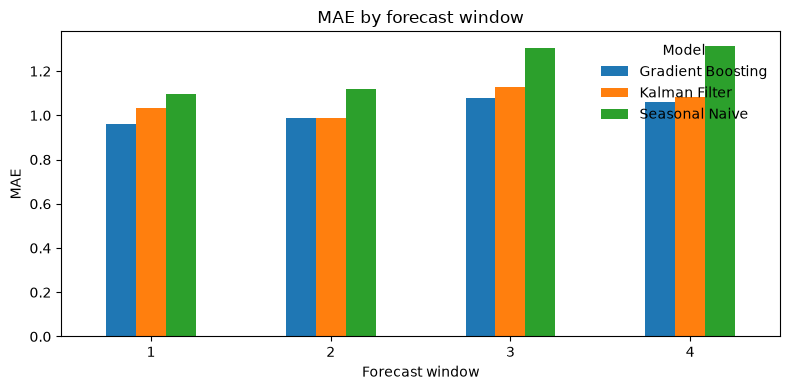

In [21]:
mae_table = by_window.pivot(
    index="Window",
    columns="Model",
    values="MAE"
)

ax = mae_table.plot(kind="bar", figsize=(8, 4))
ax.set_title("MAE by forecast window")
ax.set_xlabel("Forecast window")
ax.set_ylabel("MAE")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Model", frameon=False)

plt.tight_layout()
plt.savefig(FIGURE_DIR / "mae_by_window.png", dpi=200)
plt.show()

## 13. Find the best model in each comparison

We sort the overall table by MAE and show which model has the lowest MAE in each window. Use these outputs rather than assuming one model always wins.

In [22]:
print("Best overall model by MAE:", overall.iloc[0]["Model"])

best_by_window = by_window.loc[
    by_window.groupby("Window")["MAE"].idxmin(),
    ["Window", "Model", "MAE"]
].sort_values("Window")

display(best_by_window.reset_index(drop=True))

Best overall model by MAE: Gradient Boosting


,Window,Model,MAE
0,1,Gradient Boosting,0.961660
1,2,Gradient Boosting,0.987814
2,3,Gradient Boosting,1.078167
3,4,Gradient Boosting,1.061904


## 14. Save the results

We save the comparison tables and predictions so they can be used in the report without rerunning the models every time.

In [23]:
overall_export = overall.rename(columns={"WAPE (%)": "WAPE_percent"})
window_export = by_window.rename(columns={"WAPE (%)": "WAPE_percent"})

overall_export.to_csv(
    RESULTS_DIR / "phase1_model_comparison.csv",
    index=False
)
window_export.to_csv(
    RESULTS_DIR / "phase1_window_results.csv",
    index=False
)

all_predictions = pd.concat(
    [
        frame.assign(Model=model_name)
        for model_name, frame in models.items()
    ],
    ignore_index=True
)

all_predictions.to_csv(
    RESULTS_DIR / "phase1_predictions.csv.gz",
    index=False,
    compression="gzip"
)

print("Saved model comparison, window results, and predictions to:", RESULTS_DIR)

Saved model comparison, window results, and predictions to: /Users/palwaitejaswini/Inventory-demand-forecasting/results


## 15. What the results mean

- Lower MAE, RMSE, and WAPE indicate lower point-forecast error.
- Seasonal Naive is a simple weekly benchmark.
- Kalman estimates a changing demand level and adds approximate uncertainty intervals.
- Gradient Boosting learns patterns across series, but recursive forecasts can accumulate errors over a seven-day window.
- The best model is the one supported by the displayed results, not by expectation.

## Limitations

This experiment uses a sample of 100 series and four forecast windows, not the full M5 hierarchy. The metrics are not the official M5 WRMSSE score. The Kalman uncertainty intervals rely on a simple Gaussian approximation, and the dataset does not directly identify stockouts.

The next step could be to add a global DeepAR or LSTM model and evaluate it on the same series and forecast windows.